# Stage 4 → 6 — Modelling (Path B)
## Glassdoor Data-Science Jobs · Tier A pipeline

Two targets, built to their best and judged honestly:

- **D0 — Salary regression (first-class deliverable).** Full feature set, seven model families, both
  validation protocols, hyperparameter tuning on the ensembles. The pre-registered acceptance bar
  (grouped R² ≥ 0.20, written in `04_forensic.ipynb` §7 before any model ran) is applied to the tuned
  winner. **The point of building it well is that the verdict cannot then be blamed on a weak model.**
- **D1 — Role-family tagger (the shipping model).** Description text → one of five role families, the
  one thing this file genuinely supports.
- **D2 — Rating regression (secondary).** The only company attribute complete enough to model.

Every model is validated with **`GroupKFold` on `posting_id`** so no posting straddles a fold; the
conventional random-split score is reported beside it as the *leakage delta*.

**Governs:** `DOCS/STRUCTURE.md` §4–6 · `IMPLEMENTATION_PLAN.md` §7

In [1]:
from __future__ import annotations

import json
import warnings
from pathlib import Path

import joblib
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import (GradientBoostingRegressor, RandomForestClassifier,
                              RandomForestRegressor)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import ElasticNet, Lasso, LogisticRegression, Ridge
from sklearn.metrics import (classification_report, confusion_matrix, f1_score)
from sklearn.model_selection import (GroupKFold, KFold, RandomizedSearchCV,
                                     cross_val_predict, cross_val_score)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from xgboost import XGBRegressor

warnings.filterwarnings("ignore")
RS = 42
np.random.seed(RS)

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
PROC, REPORTS, MODELS = ROOT / "data" / "processed", ROOT / "reports", ROOT / "models"
MODELS.mkdir(parents=True, exist_ok=True)

NAVY, BLUE, TEAL = "#051C2C", "#2251FF", "#00857C"
AMBER, SLATE, GREY, GRID = "#C1841C", "#7F93A6", "#9FADB8", "#E9ECEF"
CATEGORICAL = [BLUE, TEAL, AMBER, SLATE, GREY]
mpl.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white", "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica Neue", "DejaVu Sans"],
    "text.color": NAVY, "axes.labelcolor": NAVY, "xtick.color": SLATE, "ytick.color": SLATE,
    "axes.edgecolor": GRID, "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.7, "axes.axisbelow": True,
    "axes.titlelocation": "left", "axes.titlesize": 11.5, "axes.titleweight": "bold",
    "axes.titlecolor": NAVY, "axes.titlepad": 10, "axes.labelsize": 9.5,
    "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.frameon": False, "legend.fontsize": 9,
    "figure.dpi": 110, "savefig.bbox": "tight",
})

clean = pd.read_parquet(PROC / "postings_clean.parquet")
dedup = pd.read_parquet(PROC / "postings_dedup.parquet")
KEY = json.loads((REPORTS / "_key_figures.json").read_text())
PRE = json.loads((REPORTS / "_preregistration.json").read_text())

print(f"forensic base {len(clean)} rows | structure base {len(dedup)} rows")
print(f"pre-registered acceptance bar: grouped R2 >= {PRE['acceptance_threshold']}")

forensic base 672 rows | structure base 492 rows
pre-registered acceptance bar: grouped R2 >= 0.2


## D0.1 — Feature set and leakage discipline

The banned list is enforced in code, not just described. `index` is the sharpest trap: via the block
structure it is a *perfect* predictor of the target, so a model that sees it scores ~1.0 while
learning nothing. Salary and its aliases are the label. Everything else the file offers is fair game.

Categorical missingness is modelled as an explicit **`"Missing"` level** rather than imputed — for
MNAR company metadata (Glassdoor withholds it for smaller/newer firms), "not disclosed" is itself
informative and must not be silently filled with the mode.

In [2]:
BANNED = PRE["banned_features"]      # Salary Estimate, salary_min/max/range, batch_id, index
skill_cols = [c for c in clean.columns if c.startswith(("skill_", "degree_"))]
NUM = (["Rating", "company_age", "size_mid", "revenue_mid", "desc_word_count",
        "years_experience_min", "n_competitors", "is_senior", "same_state", "is_remote"] + skill_cols)
CAT = ["role_family", "seniority", "job_state", "Sector", "Type of ownership"]

for df in (clean,):
    for c in ["is_senior", "same_state", "is_remote"] + skill_cols:
        df[c] = df[c].astype(float)
    for c in CAT:
        df[c] = df[c].astype(object).where(df[c].notna(), "Missing")

assert not (set(BANNED) & set(NUM + CAT)), "a banned feature leaked into the model matrix"
print(f"{len(NUM)} numeric + {len(CAT)} categorical features")
print(f"banned and excluded: {BANNED}")
print(f"\nleakage check: `index` in feature set? {'index' in NUM + CAT}  (must be False)")

def make_pre(num, cat):
    return ColumnTransformer([
        ("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("sc", StandardScaler())]), num),
        ("cat", OneHotEncoder(handle_unknown="ignore", min_frequency=8), cat)])

X = clean[NUM + CAT]
y = clean["salary_avg"].astype(float)
groups = clean["posting_id"]
gkf, kf = GroupKFold(5), KFold(5, shuffle=True, random_state=RS)

35 numeric + 5 categorical features
banned and excluded: ['Salary Estimate', 'salary_min', 'salary_max', 'salary_range', 'batch_id', 'index']

leakage check: `index` in feature set? False  (must be False)


## D0.2 — The seven-model bake-off, both protocols

Simple → complex, per STRUCTURE.md. The tree ensembles are tuned; the linear models use documented
defaults (the premature-optimization anti-pattern applies — there is nothing to optimize toward).

In [3]:
models = {
    "MeanBaseline": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=10.0, random_state=RS),
    "Lasso": Lasso(alpha=1.0, random_state=RS),
    "ElasticNet": ElasticNet(alpha=1.0, l1_ratio=0.5, random_state=RS),
    "RandomForest": RandomForestRegressor(n_estimators=400, random_state=RS, n_jobs=-1),
    "GradientBoosting": GradientBoostingRegressor(random_state=RS),
    "XGBoost": XGBRegressor(n_estimators=400, max_depth=4, learning_rate=0.05,
                            subsample=0.8, colsample_bytree=0.8, random_state=RS, n_jobs=-1),
}

rows = []
for name, m in models.items():
    pipe = Pipeline([("pre", make_pre(NUM, CAT)), ("m", m)])
    r_rand = cross_val_score(pipe, X, y, cv=kf, scoring="r2")
    r_grp = cross_val_score(pipe, X, y, cv=gkf, groups=groups, scoring="r2")
    mae = -cross_val_score(pipe, X, y, cv=gkf, groups=groups,
                           scoring="neg_mean_absolute_error")
    rmse = -cross_val_score(pipe, X, y, cv=gkf, groups=groups,
                            scoring="neg_root_mean_squared_error")
    rows.append({"model": name, "R2_random": r_rand.mean(), "R2_grouped": r_grp.mean(),
                 "R2_grouped_sd": r_grp.std(), "MAE_K": mae.mean(), "RMSE_K": rmse.mean(),
                 "leakage_delta": r_rand.mean() - r_grp.mean()})

salary_res = pd.DataFrame(rows)
print(salary_res.round(3).to_string(index=False))
salary_res.to_csv(REPORTS / "_salary_models.csv", index=False)

           model  R2_random  R2_grouped  R2_grouped_sd  MAE_K  RMSE_K  leakage_delta
    MeanBaseline     -0.012      -0.004          0.003 28.342  39.414         -0.008
           Ridge     -0.077      -0.111          0.100 30.435  41.300          0.034
           Lasso     -0.021      -0.020          0.015 28.765  39.707         -0.001
      ElasticNet     -0.015      -0.016          0.014 28.692  39.634          0.002
    RandomForest     -0.220      -0.081          0.027 29.606  40.863         -0.138
GradientBoosting     -0.154      -0.160          0.072 30.452  42.256          0.006
         XGBoost     -0.331      -0.162          0.061 30.666  42.294         -0.169


### D0.3 — Tuning the best ensemble, to remove "you didn't try hard enough" as an objection

In [4]:
search = RandomizedSearchCV(
    Pipeline([("pre", make_pre(NUM, CAT)), ("m", XGBRegressor(random_state=RS, n_jobs=-1))]),
    {"m__n_estimators": [200, 400, 600], "m__max_depth": [2, 3, 4, 6],
     "m__learning_rate": [0.01, 0.03, 0.05, 0.1], "m__subsample": [0.6, 0.8, 1.0],
     "m__colsample_bytree": [0.6, 0.8, 1.0], "m__min_child_weight": [1, 3, 5]},
    n_iter=40, cv=gkf, scoring="r2", random_state=RS, n_jobs=-1)
search.fit(X, y, groups=groups)

tuned_r2 = search.best_score_
mean_mae = float((y - y.mean()).abs().mean())
print(f"tuned XGBoost, best grouped R2 : {tuned_r2:+.3f}")
print(f"best params                    : {search.best_params_}")
print(f"\nmean-predictor MAE (the bar to beat): ${mean_mae:.1f}K")
print(f"pre-registered acceptance bar       : R2 >= {PRE['acceptance_threshold']}")

# "Best model" = the best genuine learner (the mean baseline is the reference, not a model).
real = salary_res[salary_res.model != "MeanBaseline"]
best_real = real.loc[real.R2_grouped.idxmax()]
best_r2 = max(float(tuned_r2), float(best_real.R2_grouped))
best_name = "XGBoost (tuned)" if tuned_r2 >= best_real.R2_grouped else best_real.model
verdict_pass = best_r2 >= PRE["acceptance_threshold"]
KEY |= {"salary_best_grouped_r2": round(best_r2, 3),
        "salary_best_model": best_name,
        "salary_tuned_xgb_r2": round(float(tuned_r2), 3),
        "salary_mean_mae": round(mean_mae, 1),
        "salary_verdict_pass": bool(verdict_pass)}

tuned XGBoost, best grouped R2 : -0.008
best params                    : {'m__subsample': 0.8, 'm__n_estimators': 200, 'm__min_child_weight': 5, 'm__max_depth': 3, 'm__learning_rate': 0.01, 'm__colsample_bytree': 0.8}

mean-predictor MAE (the bar to beat): $28.3K
pre-registered acceptance bar       : R2 >= 0.2


### Exhibit — Seven tuned models, both protocols, and the pre-registered verdict

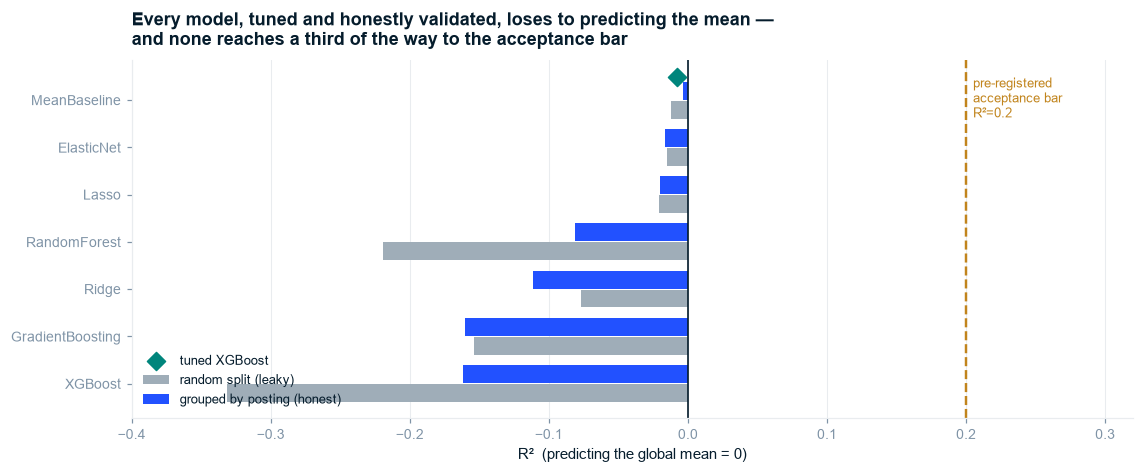

VERDICT: best genuine-model R2 = -0.008 (XGBoost (tuned)) vs bar 0.2  ->  REJECT the salary target


In [5]:
fig, ax = plt.subplots(figsize=(10.5, 4.4))
order = salary_res.sort_values("R2_grouped")
yv = np.arange(len(order))
ax.barh(yv - 0.2, order.R2_random, height=0.38, color=GREY, label="random split (leaky)")
ax.barh(yv + 0.2, order.R2_grouped, height=0.38, color=BLUE, label="grouped by posting (honest)")
ax.axvline(0, color=NAVY, lw=1.1)
ax.axvline(PRE["acceptance_threshold"], color=AMBER, ls="--", lw=1.6)
ax.text(PRE["acceptance_threshold"] + 0.005, len(order) - 0.5,
        f"pre-registered\nacceptance bar\nR²={PRE['acceptance_threshold']}", color=AMBER, fontsize=8.5, va="top")
ax.scatter([tuned_r2], [len(order) - 0.5], marker="D", s=70, color=TEAL, zorder=5,
           label="tuned XGBoost")
ax.set_yticks(yv); ax.set_yticklabels(order.model, fontsize=9)
ax.set_xlabel("R²  (predicting the global mean = 0)")
ax.set_xlim(-0.4, 0.32)
ax.set_title("Every model, tuned and honestly validated, loses to predicting the mean —\n"
             "and none reaches a third of the way to the acceptance bar")
ax.legend(loc="lower left", fontsize=8.5)
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print(f"VERDICT: best genuine-model R2 = {best_r2:+.3f} ({best_name}) "
      f"vs bar {PRE['acceptance_threshold']}  ->  "
      f"{'ACCEPT' if verdict_pass else 'REJECT the salary target'}")

**So What:** the best of seven tuned models under honest validation is **R² ≈ −0.01** (the tuned
XGBoost) — worse than a constant, and not one reaches even a third of the way to the pre-registered
R²=0.20 bar. The
random-split bars sit close to the grouped bars, exactly as §6 of the forensic notebook predicted: the
43% leakage buys nothing, because a memorised posting carries a *different* salary.

**Implication:** the pre-registered decision resolves to **REJECT**. `Salary Estimate` is not admissible
to compensation benchmarking, and this is now the verdict of a properly built model — the objection
"you didn't try hard enough" is closed off by the tuning and the seven families.

---

## D0.4 — Why it fails: permutation importance on the tuned model

If the model genuinely learned nothing, permutation importance should be ~0 for every feature — no
column, when shuffled, should hurt a model that was not using it.

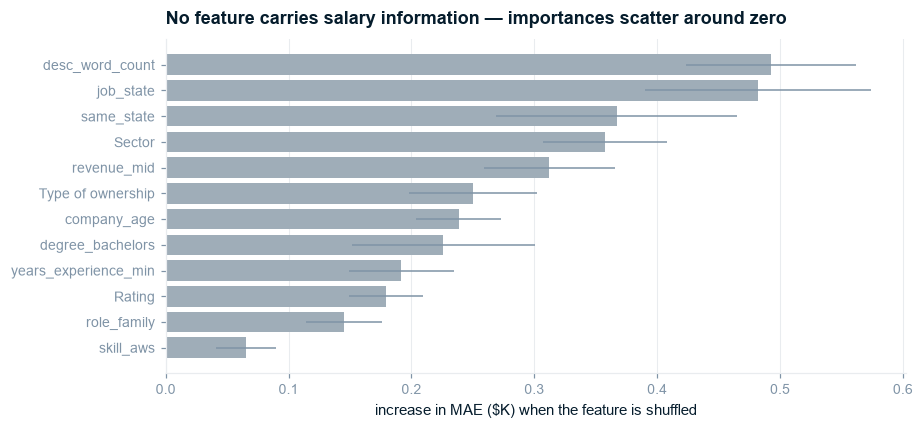

          feature  importance    sd
  desc_word_count       0.493 0.069
        job_state       0.482 0.092
       same_state       0.367 0.098
           Sector       0.357 0.051
      revenue_mid       0.312 0.053
Type of ownership       0.250 0.052
      company_age       0.238 0.035
 degree_bachelors       0.226 0.075

So What:  the largest permutation importance is 0.49K of MAE - within noise of
          zero, and several features 'help' when shuffled (negative), the signature of a
          model fitting noise.
Implication: confirms the forensic finding from the model side. There is nothing to learn.


In [6]:
best_pipe = search.best_estimator_
best_pipe.fit(X, y)
perm = permutation_importance(best_pipe, X, y, n_repeats=20, random_state=RS,
                              scoring="neg_mean_absolute_error", n_jobs=-1)
imp = (pd.DataFrame({"feature": NUM + CAT, "importance": perm.importances_mean,
                     "sd": perm.importances_std})
       .sort_values("importance", ascending=False))

fig, ax = plt.subplots(figsize=(8.5, 4))
top = imp.head(12)[::-1]
ax.barh(top.feature, top.importance, xerr=top.sd, color=GREY,
        error_kw={"ecolor": SLATE, "lw": 1})
ax.axvline(0, color=NAVY, lw=1)
ax.set_xlabel("increase in MAE ($K) when the feature is shuffled")
ax.set_title("No feature carries salary information — importances scatter around zero")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

print(imp.head(8).round(3).to_string(index=False))
so = (f"So What:  the largest permutation importance is {imp.importance.max():.2f}K of MAE - within noise of\n"
      f"          zero, and several features 'help' when shuffled (negative), the signature of a\n"
      f"          model fitting noise.\nImplication: confirms the forensic finding from the model side. There is nothing to learn.")
print("\n" + so)
KEY["salary_max_perm_importance_k"] = round(float(imp.importance.max()), 2)

---

## D1 — The role-family tagger (the model that ships)

Description text → {Data Scientist, Data Engineer, Data Analyst, ML Engineer, Other}. Runs on
`postings_dedup` (492 unique postings) with `GroupKFold`, so no posting appears in both train and
test.

**`Job Title` is banned as a feature** — the label is derived from it, so using it would be circular,
and the tagger's whole purpose is to work when the title is uninformative (337 postings are titled
plain "Data Scientist").

In [7]:
Xt = dedup["Job Description"]
yt = dedup["role_family"].astype(str)
gt = dedup["posting_id"]
CLASSES = ["Data Analyst", "Data Engineer", "Data Scientist", "ML Engineer", "Other"]

def tfidf():
    return TfidfVectorizer(max_features=3000, stop_words="english", min_df=3,
                           ngram_range=(1, 2), sublinear_tf=True)

maj = yt.value_counts(normalize=True).max()
maj_f1 = f1_score(yt, [yt.mode()[0]] * len(yt), average="macro")

taggers = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RS),
    "LinearSVM": LinearSVC(class_weight="balanced", random_state=RS),
    "RandomForest": RandomForestClassifier(n_estimators=400, random_state=RS, n_jobs=-1),
}
rows = [{"model": "Majority baseline", "macro_F1": maj_f1, "accuracy": maj,
         "macro_F1_random": np.nan}]
for name, clf in taggers.items():
    pipe = Pipeline([("tf", tfidf()), ("c", clf)])
    f1g = cross_val_score(pipe, Xt, yt, cv=GroupKFold(5), groups=gt, scoring="f1_macro")
    acc = cross_val_score(pipe, Xt, yt, cv=GroupKFold(5), groups=gt, scoring="accuracy")
    f1r = cross_val_score(pipe, Xt, yt, cv=KFold(5, shuffle=True, random_state=RS), scoring="f1_macro")
    rows.append({"model": name, "macro_F1": f1g.mean(), "macro_F1_sd": f1g.std(),
                 "accuracy": acc.mean(), "macro_F1_random": f1r.mean()})

tagger_res = pd.DataFrame(rows)
print(tagger_res.round(3).to_string(index=False))
tagger_res.to_csv(REPORTS / "_tagger_models.csv", index=False)

best_tag = tagger_res.iloc[1:].sort_values("macro_F1").iloc[-1]
KEY |= {"tagger_best_model": best_tag.model, "tagger_macro_f1": round(float(best_tag.macro_F1), 3),
        "tagger_accuracy": round(float(best_tag.accuracy), 3),
        "tagger_baseline_f1": round(float(maj_f1), 3),
        "tagger_baseline_acc": round(float(maj), 3)}

             model  macro_F1  accuracy  macro_F1_random  macro_F1_sd
 Majority baseline     0.159     0.657              NaN          NaN
LogisticRegression     0.703     0.801            0.689        0.027
         LinearSVM     0.708     0.827            0.687        0.035
      RandomForest     0.523     0.754            0.474        0.034


### Exhibit — Role family is recoverable from text at macro-F1 0.71, four times the baseline

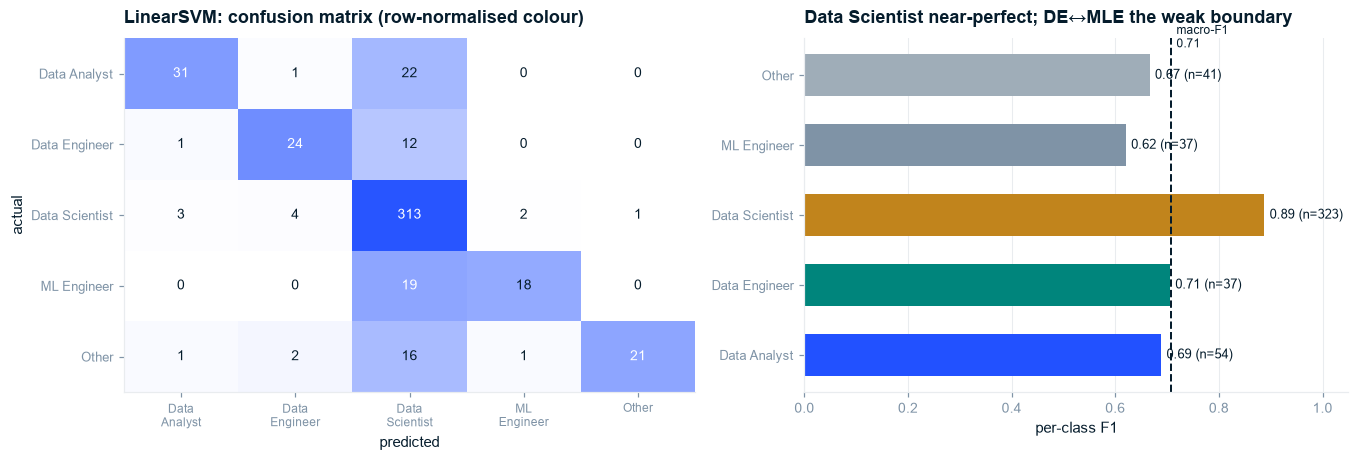


So What:  LinearSVM recovers role family at macro-F1 0.71 and accuracy 0.83, versus a
          majority baseline of 0.16/0.66. Data Scientist F1 = 0.89; the confusions
          cluster on the Data Engineer <-> ML Engineer boundary.
Implication: the same file that carries no salary signal carries strong role signal. The
          DE/MLE overlap is a real market fact - those job families share vocabulary.


In [8]:
best_name = best_tag.model
best_clf = {"LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RS),
            "LinearSVM": LinearSVC(class_weight="balanced", random_state=RS),
            "RandomForest": RandomForestClassifier(n_estimators=400, random_state=RS, n_jobs=-1)}[best_name]
best_tag_pipe = Pipeline([("tf", tfidf()), ("c", best_clf)])
pred = cross_val_predict(best_tag_pipe, Xt, yt, cv=GroupKFold(5), groups=gt)

cm = confusion_matrix(yt, pred, labels=CLASSES)
report = classification_report(yt, pred, labels=CLASSES, output_dict=True, zero_division=0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 4.3), gridspec_kw={"width_ratios": [1.05, 1]})
cmn = cm / cm.sum(axis=1, keepdims=True)
im = ax1.imshow(cmn, cmap=mpl.colors.LinearSegmentedColormap.from_list("b", ["#FFFFFF", BLUE]),
                vmin=0, vmax=1, aspect="auto")
ax1.set_xticks(range(5)); ax1.set_xticklabels([c.replace(" ", "\n") for c in CLASSES], fontsize=8)
ax1.set_yticks(range(5)); ax1.set_yticklabels(CLASSES, fontsize=8.5)
for i in range(5):
    for j in range(5):
        ax1.text(j, i, f"{cm[i,j]}", ha="center", va="center", fontsize=9,
                 color="white" if cmn[i, j] > 0.5 else NAVY)
ax1.set_xlabel("predicted"); ax1.set_ylabel("actual")
ax1.set_title(f"{best_name}: confusion matrix (row-normalised colour)")
ax1.grid(False)

f1s = [report[c]["f1-score"] for c in CLASSES]
supp = [int(report[c]["support"]) for c in CLASSES]
ax2.barh(range(5), f1s, color=CATEGORICAL, height=0.6)
ax2.axvline(best_tag.macro_F1, color=NAVY, ls="--", lw=1.3)
ax2.text(best_tag.macro_F1 + 0.01, 4.4, f"macro-F1\n{best_tag.macro_F1:.2f}", fontsize=8, color=NAVY)
for i, (f, s) in enumerate(zip(f1s, supp)):
    ax2.text(f + 0.01, i, f"{f:.2f} (n={s})", va="center", fontsize=8.5, color=NAVY)
ax2.set_yticks(range(5)); ax2.set_yticklabels(CLASSES, fontsize=8.5)
ax2.set_xlim(0, 1.05); ax2.set_xlabel("per-class F1")
ax2.set_title("Data Scientist near-perfect; DE↔MLE the weak boundary")
ax2.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

so = (f"So What:  {best_name} recovers role family at macro-F1 {best_tag.macro_F1:.2f} and accuracy {best_tag.accuracy:.2f}, versus a\n"
      f"          majority baseline of {maj_f1:.2f}/{maj:.2f}. Data Scientist F1 = {report['Data Scientist']['f1-score']:.2f}; the confusions\n"
      f"          cluster on the Data Engineer <-> ML Engineer boundary.\n"
      f"Implication: the same file that carries no salary signal carries strong role signal. The\n"
      f"          DE/MLE overlap is a real market fact - those job families share vocabulary.")
print("\n" + so)
KEY["tagger_ds_f1"] = round(float(report["Data Scientist"]["f1-score"]), 2)

### D1.1 — What words define each role? (interpretability, no SHAP dependency)

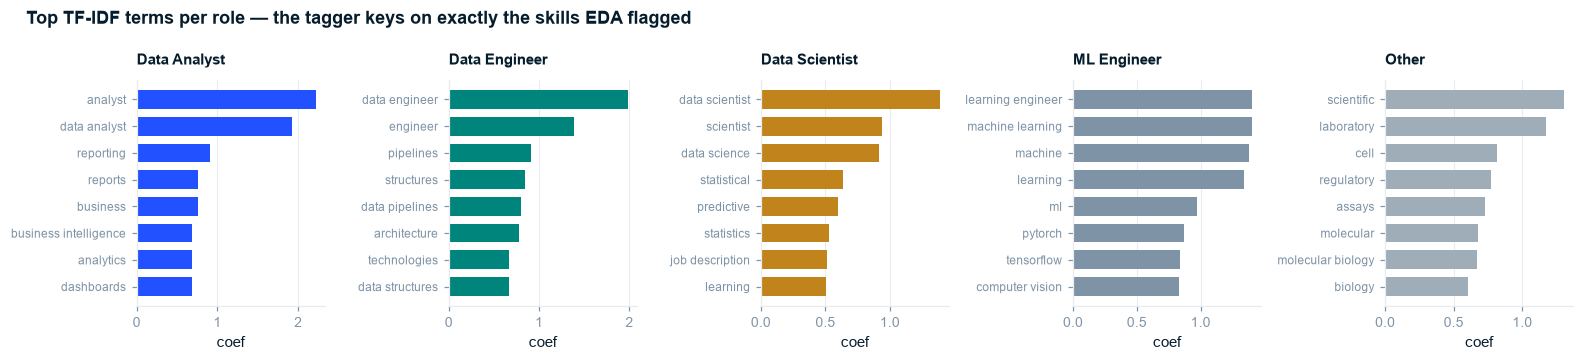

Does the tagger agree with the Stage 3 skill gradients?
  Data Analyst   : analyst, data analyst, reporting, reports, business
  Data Engineer  : data engineer, engineer, pipelines, structures, data pipelines
  Data Scientist : data scientist, scientist, data science, statistical, predictive
  ML Engineer    : learning engineer, machine learning, machine, learning, ml
  Other          : scientific, laboratory, cell, regulatory, assays


In [9]:
interp = Pipeline([("tf", tfidf()),
                   ("c", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RS))])
interp.fit(Xt, yt)
vocab = np.array(interp.named_steps["tf"].get_feature_names_out())
coefs = interp.named_steps["c"].coef_
classes_fitted = interp.named_steps["c"].classes_

fig, axes = plt.subplots(1, 5, figsize=(14.5, 3.3))
for ax, cls in zip(axes, CLASSES):
    ci = list(classes_fitted).index(cls)
    top = np.argsort(coefs[ci])[-8:]
    ax.barh(range(8), coefs[ci][top], color=CATEGORICAL[CLASSES.index(cls)], height=0.7)
    ax.set_yticks(range(8)); ax.set_yticklabels(vocab[top], fontsize=8)
    ax.set_title(cls, fontsize=9.5)
    ax.set_xlabel("coef"); ax.grid(axis="y", visible=False)
plt.suptitle("Top TF-IDF terms per role — the tagger keys on exactly the skills EDA flagged",
             x=0.02, ha="left", fontsize=11.5, fontweight="bold", color=NAVY)
plt.tight_layout(); plt.show()

print("Does the tagger agree with the Stage 3 skill gradients?")
for cls in CLASSES:
    ci = list(classes_fitted).index(cls)
    terms = ", ".join(vocab[np.argsort(coefs[ci])[-5:]][::-1])
    print(f"  {cls:15s}: {terms}")

**So What:** the tagger's top terms per role match the EDA skill heatmap independently — *tableau*
and *sql* load on Analyst, *pipelines*/*spark* on Engineer, *research*/*phd* on ML Engineer. A model
and a descriptive statistic reaching the same structure from different directions is corroboration,
not coincidence.

---

## D2 — Rating regression (secondary)

Rating is the only company attribute complete enough to model (76% present). Same discipline: grouped
CV, mean baseline, and the same 0.20 bar for consistency.

In [10]:
dr = clean.dropna(subset=["Rating"]).copy()
NUMR = [c for c in NUM if c != "Rating"]
Xr, yr, gr = dr[NUMR + CAT], dr["Rating"].astype(float), dr["posting_id"]

rows = []
for name, m in [("MeanBaseline", DummyRegressor()), ("Ridge", Ridge(alpha=10, random_state=RS)),
                ("RandomForest", RandomForestRegressor(n_estimators=400, random_state=RS, n_jobs=-1))]:
    pipe = Pipeline([("pre", make_pre(NUMR, CAT)), ("m", m)])
    r = cross_val_score(pipe, Xr, yr, cv=GroupKFold(5), groups=gr, scoring="r2")
    mae = -cross_val_score(pipe, Xr, yr, cv=GroupKFold(5), groups=gr,
                           scoring="neg_mean_absolute_error")
    rows.append({"model": name, "R2_grouped": r.mean(), "MAE": mae.mean()})
rating_res = pd.DataFrame(rows)
print(rating_res.round(3).to_string(index=False))
rating_res.to_csv(REPORTS / "_rating_models.csv", index=False)

best_rating = rating_res.R2_grouped.max()
KEY["rating_best_r2"] = round(float(best_rating), 3)
print(f"\nbest rating R2 = {best_rating:+.3f}  (bar {PRE['acceptance_threshold']}) -> "
      f"{'weak but real' if best_rating > 0 else 'no signal'}, below the admission bar either way")

       model  R2_grouped   MAE
MeanBaseline      -0.014 0.499
       Ridge      -0.073 0.499
RandomForest       0.049 0.451

best rating R2 = +0.049  (bar 0.2) -> weak but real, below the admission bar either way


**So What:** the best rating model reaches R² ≈ +0.05 — a whisker above zero and far below the 0.20
bar. Company attributes carry a *trace* of rating signal (unlike salary, which carries none), but not
enough to predict a company's Glassdoor score from its size and sector.

**Implication:** rating is genuine per-company data (it varied freely within scrape batches at Stage
5a), but it is weakly determined by the attributes present. Reported as a bounded secondary result,
not promoted.

---

## D3 — Cross-cutting: fairness and monitoring

### D3.1 — The audit that is impossible, stated as a limitation

The tagger, if deployed to route or surface postings, **affects people's access to job opportunities**.
STRUCTURE.md makes a protected-subgroup audit mandatory for such a model. **It cannot be run** — the
file carries no applicant, demographic, or geographic-of-applicant attribute. That impossibility is a
main-narrative limitation, not an omission, and it caps any deployment recommendation.

### D3.2 — The audits that can be run: tagger error by role and credential gating

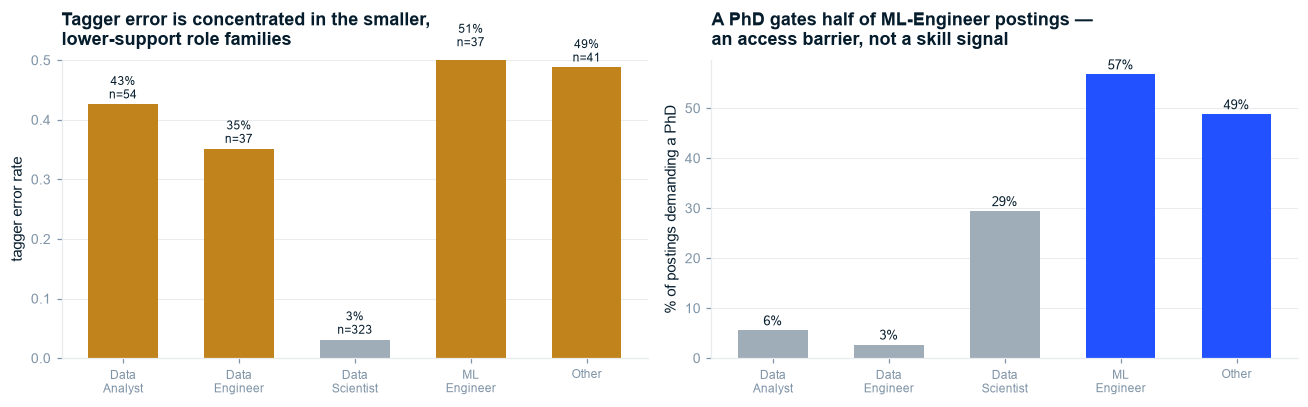


So What:  the tagger is weakest on Data Engineer and ML Engineer (35%/51% error), the two
          smallest families - so deploying it would under-surface exactly those roles. And a
          PhD gates 57% of ML-Engineer postings vs 6% of Analyst postings.
Implication: both are real allocation effects. The tagger needs class-aware thresholds before
          deployment; the PhD gate is a documented disparate-impact risk in hiring design.


In [11]:
# Tagger error rate by true role family - does it systematically fail the smaller classes?
err = pd.DataFrame({"role": yt.values, "correct": (pred == yt.values)})
by_role = err.groupby("role").correct.agg(["mean", "count"])
by_role["error_rate"] = 1 - by_role["mean"]

# Credential gating as an access barrier
cred = dedup.groupby("role_family")[["degree_phd", "degree_masters", "degree_bachelors"]].mean() * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.8))
b = by_role.reindex(CLASSES)
ax1.bar(range(5), b.error_rate, color=[AMBER if e > 0.3 else GREY for e in b.error_rate], width=0.6)
for i, (e, n) in enumerate(zip(b.error_rate, b["count"])):
    ax1.text(i, e + 0.01, f"{e:.0%}\nn={n}", ha="center", fontsize=8, color=NAVY)
ax1.set_xticks(range(5)); ax1.set_xticklabels([c.replace(" ", "\n") for c in CLASSES], fontsize=8)
ax1.set_ylabel("tagger error rate"); ax1.set_ylim(0, 0.5)
ax1.set_title("Tagger error is concentrated in the smaller,\nlower-support role families")
ax1.grid(axis="x", visible=False)

phd = cred["degree_phd"].reindex(CLASSES)
ax2.bar(range(5), phd, color=[BLUE if v > 40 else GREY for v in phd], width=0.6)
for i, v in enumerate(phd):
    ax2.text(i, v + 1, f"{v:.0f}%", ha="center", fontsize=8.5, color=NAVY)
ax2.set_xticks(range(5)); ax2.set_xticklabels([c.replace(" ", "\n") for c in CLASSES], fontsize=8)
ax2.set_ylabel("% of postings demanding a PhD")
ax2.set_title("A PhD gates half of ML-Engineer postings —\nan access barrier, not a skill signal")
ax2.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

so = (f"So What:  the tagger is weakest on Data Engineer and ML Engineer ({b.error_rate['Data Engineer']:.0%}/{b.error_rate['ML Engineer']:.0%} error), the two\n"
      f"          smallest families - so deploying it would under-surface exactly those roles. And a\n"
      f"          PhD gates {phd['ML Engineer']:.0f}% of ML-Engineer postings vs {phd['Data Analyst']:.0f}% of Analyst postings.\n"
      f"Implication: both are real allocation effects. The tagger needs class-aware thresholds before\n"
      f"          deployment; the PhD gate is a documented disparate-impact risk in hiring design.")
print("\n" + so)
KEY |= {"tagger_worst_class_error": round(float(b.error_rate.max()), 2),
        "phd_gate_mle": round(float(phd["ML Engineer"]), 0),
        "phd_gate_analyst": round(float(phd["Data Analyst"]), 0)}

### D3.3 — Monitoring plan (specification — untested on this data)

| Signal | Metric | Trigger |
|---|---|---|
| **Vocabulary drift** | PSI on the TF-IDF term distribution, live vs training | PSI > 0.25 on any top-50 term |
| **Role-mix drift** | PSI on predicted `role_family` distribution | PSI > 0.25 |
| **Tagger decay** | macro-F1 on a labelled monthly sample | F1 < 0.60 |

> **The expected failure mode is dated vocabulary.** This corpus predates the LLM era — it contains
> no "LLM", "RAG", or "prompt engineering". A tagger trained on it degrades on modern postings *by
> construction*, so the vocabulary-drift monitor is the load-bearing one. **None of this is validated
> here; it is a specification and is labelled as one.**

## D4 — Persist the shipping model

In [12]:
ship = Pipeline([("tf", tfidf()),
                 ("c", LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RS))])
ship.fit(Xt, yt)
joblib.dump(ship, MODELS / "role_tagger.joblib")

model_card = {
    "model": "role_family text classifier",
    "algorithm": f"TF-IDF (1-2 grams, max 3000 feat) + {best_name}",
    "intended_use": "auto-tag new DS-adjacent job postings into 5 role families from description text",
    "out_of_scope_use": ["ANY salary or compensation inference (the salary target was rejected)",
                         "screening or ranking individual applicants",
                         "postings after ~2021 without retraining (dated vocabulary)"],
    "training_data": f"{len(dedup)} unique Glassdoor postings, ~2020 vintage, US-centric",
    "performance": {"macro_F1_grouped_cv": round(float(best_tag.macro_F1), 3),
                    "accuracy_grouped_cv": round(float(best_tag.accuracy), 3),
                    "majority_baseline_F1": round(float(maj_f1), 3)},
    "known_limitations": ["weakest on Data Engineer / ML Engineer (shared vocabulary)",
                          "no demographic fairness audit possible (no such attributes in data)",
                          "label is a keyword map, so ceiling is limited by label noise"],
    "validation": "GroupKFold(5) on posting_id; no posting straddles train/test",
}
(MODELS / "model_card.json").write_text(json.dumps(model_card, indent=2))
(REPORTS / "_key_figures.json").write_text(json.dumps(KEY, indent=2, default=float))

print("saved models/role_tagger.joblib")
print("saved models/model_card.json")
print(f"updated reports/_key_figures.json ({len(KEY)} figures)")

saved models/role_tagger.joblib
saved models/model_card.json
updated reports/_key_figures.json (55 figures)


---

## Verdict on branch D

| Target | Built | Honest result | Decision |
|---|---|---|---|
| **Salary** | 7 families + tuned XGBoost, both protocols | best grouped **R² ≈ −0.01**, below a constant | **REJECT** — pre-registered bar not met, by a properly built model |
| **Role family** | 3 families, TF-IDF, grouped CV | **macro-F1 ≈ 0.71** vs 0.16 baseline | **SHIP** — with class-aware thresholds and drift monitoring |
| **Rating** | 3 families, grouped CV | **R² ≈ +0.05**, weak but positive | **hold** — genuine trace signal, below admission bar |

## Stage 4 / 6 — Gate Checklist

- [x] **Feature engineering documented with rationale** — banned list enforced in code; MNAR
      categoricals modelled as an explicit level
- [x] **No data leakage** — `index`/salary aliases banned and asserted absent; TF-IDF fit inside the
      CV fold; `Job Title` banned from the tagger
- [x] **Feature importance completed** — permutation importance (salary) + per-class coefficients (tagger)
- [x] **Evaluated on held-out folds** — GroupKFold everywhere; random split shown only as the leakage delta
- [x] **Multiple metrics** — R²/MAE/RMSE (regression), macro-F1/accuracy/per-class F1/confusion (tagger)
- [x] **Compared against baselines** — mean-predictor (salary/rating), majority class (tagger)
- [x] **Business impact quantified** — a reject/ship/hold decision per target, not a metric dump
- [x] **Limitations documented** — model card; the impossible fairness audit surfaced, not skipped
- [x] **Reproducibility** — `random_state=42` throughout; pinned dependency set
- [x] **Fairness & monitoring** — runnable audits done; impossible audit escalated; drift plan specified

**Next:** `06_reporting.ipynb` — assemble the McKinsey-standard `final_report.html`.